In [1]:
import os
import seaborn as sns
import matplotlib.pyplot as plt 
import numpy as np 
import pandas as pd 
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
# Cargar el dataset sin anomalías (del Notebook 01)
df = pd.read_csv(
    "../data/processed/docentes_enoe_sin_anomalias.csv",
    na_values=["\\N", '\ N', " ", "", "NA", "NaN"],
)

<>:4: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:4: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
C:\Users\David\AppData\Local\Temp\ipykernel_2752\2377932299.py:4: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
  na_values=["\\N", '\ N', " ", "", "NA", "NaN"],


In [3]:
# Preparar variables econométricas
cols_modelo = ["ingocup", "hrsocup", "eda", "sex", "cs_p13_1", "p3a"]

In [4]:
# Utilizaremos el modelo de ecuacíon salarial Mincer econometrica (usanmos la transformada logaritmica) 

for col in cols_modelo:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Depurar filas con nulos y filtrar salarios y horas positivas
df_model = df.dropna(subset=cols_modelo).copy()
df_model = df_model[(df_model["ingocup"] > 0) & (df_model["hrsocup"] > 0)]

print(f"muestra efectiva valida para la ecuación de Mincer: {len(df_model)} docentes.")

# Variable Dummy de género (1 = Mujer, 0 = Hombre)
df_model["mujer"] = (
    (df_model["sex"] == 2.0) | (df_model["sex"] == 2)
).astype(int)

# Experiencia / Edad cuadrática (retornos decrecientes de Mincer)
df_model["eda2"] = df_model["eda"] ** 2

# Logaritmo natural del ingreso mensual (variable dependiente)
df_model["log_ingocup"] = np.log(df_model["ingocup"])

# Formular y ajustar el modelo minceriano con errores estándar robustos (HC3)
formula_mincer = (f"log_ingocup ~ mujer + hrsocup + eda + eda2 + C(cs_p13_1) + C(p3a)")


modelo_mincer = smf.ols(formula_mincer, data=df_model).fit(cov_type="HC3")

# Resumen
print("\n=== RESUMEN DE LA ECUACIÓN SALARIAL DE MINCER ===") 
print(modelo_mincer.summary().tables[1])




muestra efectiva valida para la ecuación de Mincer: 1097 docentes.

=== RESUMEN DE LA ECUACIÓN SALARIAL DE MINCER ===
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              7.6895      0.390     19.725      0.000       6.925       8.454
C(cs_p13_1)[T.3.0]     0.1209      0.378      0.320      0.749      -0.621       0.863
C(cs_p13_1)[T.4.0]     0.1297      0.351      0.369      0.712      -0.559       0.818
C(cs_p13_1)[T.5.0]     0.5643      0.360      1.568      0.117      -0.141       1.270
C(cs_p13_1)[T.6.0]     0.1362      0.366      0.372      0.710      -0.581       0.854
C(cs_p13_1)[T.7.0]     0.4854      0.344      1.409      0.159      -0.190       1.161
C(cs_p13_1)[T.8.0]     0.5719      0.346      1.653      0.098      -0.106       1.250
C(cs_p13_1)[T.9.0]     0.5901      0.349      1.690      0.091      -0.094       1.274
C(p3a)[T.2] 

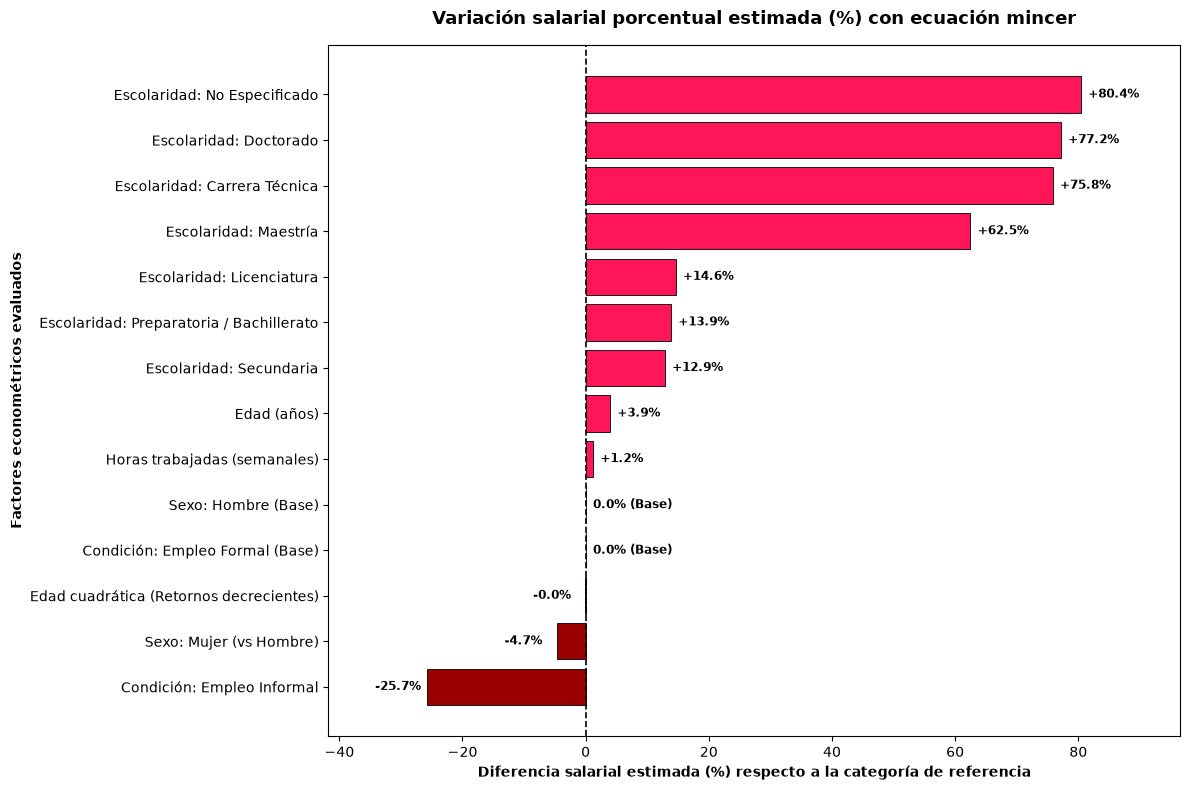

In [5]:
# Diccionario de traducción de las columnas
diccionario_nombres = {
    # Variables continuas
    "hrsocup": "Horas trabajadas (semanales)",
    "eda": "Edad (años)",
    "eda2": "Edad cuadrática (Retornos decrecientes)",
    # Demográficas y laborales (dummies)
    "mujer": "Sexo: Mujer (vs Hombre)",
    "C(p3a)[T.2]": "Condición: Empleo Informal",
    # Niveles Educativos (cs_p13_1)
    "C(cs_p13_1)[T.3.0]": "Escolaridad: Secundaria", 
    "C(cs_p13_1)[T.4.0]": "Escolaridad: Preparatoria / Bachillerato", 
    "C(cs_p13_1)[T.5.0]": "Escolaridad: Carrera Técnica", 
    "C(cs_p13_1)[T.6.0]": "Escolaridad: Licenciatura", 
    "C(cs_p13_1)[T.7.0]": "Escolaridad: Maestría", 
    "C(cs_p13_1)[T.8.0]": "Escolaridad: Doctorado", 
    "C(cs_p13_1)[T.9.0]": "Escolaridad: No Especificado",
}

# Extraer coeficientes y calcular variaciones porcentual % = (exp(b) - 1)
params = modelo_mincer.params.drop("Intercept")
df_mincer_coef = pd.DataFrame(
    {
        "Variable_Cod": params.index,
        "Cambio_Porcentual": (np.exp(params.values) - 1) * 100,
        "Es_Base": False,
    }
)

df_mincer_coef["Variable_Label"] = (
    df_mincer_coef["Variable_Cod"]
    .map(diccionario_nombres)
    .fillna(df_mincer_coef["Variable_Cod"])
)

# Incluir explícitamente las categorías base (0.0%)
filas_base = pd.DataFrame(
    [
        {
            "Variable_Label": "Sexo: Hombre (Base)",
            "Cambio_Porcentual": 0.0,
            "Es_Base":True,
        },
        {
            "Variable_Label": "Condición: Empleo Formal (Base)",
            "Cambio_Porcentual": 0.0,
            "Es_Base":True,
        }
    ]
)

df_grafica = pd.concat([df_mincer_coef, filas_base], ignore_index=True)
df_grafica = df_grafica.sort_values(by="Cambio_Porcentual", ascending=True)

colores = []
for _, row in df_grafica.iterrows():
    if row["Es_Base"]:
        colores.append("#7f7f7f")
    elif row["Cambio_Porcentual"] >= 0:
        colores.append("#ff1659")
    else:
        colores.append("#9b0000")

os.makedirs("../outputs/figures", exist_ok=True)
plt.figure(figsize=(12, 8))

bars = plt.barh(
    df_grafica["Variable_Label"],
    df_grafica["Cambio_Porcentual"],
    color=colores,
    edgecolor="black",
    linewidth=0.6,
)

plt.axvline(0, color="black", linestyle="--", linewidth=1.2)

for bar in bars:
    width = bar.get_width()
    offset = 1.2 if width >= 0 else -8.5
    text_val = "0.0% (Base)" if width == 0 else f"{width:+.1f}%"
    plt.text(
        width + offset,
        bar.get_y() + bar.get_height() / 2,
        text_val,
        va="center",
        fontsize=8.5,
        fontweight="bold",
        color="black",
    )

max_val = max(abs(df_grafica["Cambio_Porcentual"]))
margin = max_val * 0.2
min_x = df_grafica["Cambio_Porcentual"].min()
max_x = df_grafica["Cambio_Porcentual"].max()
plt.xlim(min(min_x -margin, -margin), max(max_x + margin, margin))

plt.title(
    "Variación salarial porcentual estimada (%) con ecuación mincer",
    fontsize=13,
    fontweight="bold",
    pad=15,
)

plt.xlabel(
    "Diferencia salarial estimada (%) respecto a la categoría de referencia",
    fontweight="bold",
)

plt.ylabel("Factores econométricos evaluados", fontweight="bold")
plt.tight_layout()

plt.savefig("../outputs/figures/mincer_coeficientes_porcentaje.png", dpi=300)
plt.show()